# Applied Statistics: Exploring the Iris Dataset

## Introduction

The Iris dataset contains information about three different types of flowers.

In this notebook, I will use Python to examine petal measurements and explore how they differ between the species.

The first part of the analysis focuses on petal length, using histograms and basic statistical calculations.

In [1]:
# Import necessary libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
# Load the dataset with seaborn and Iris dataset
# https://www.geeksforgeeks.org/python/python-seaborn-load_dataset-method/
iris_df = sns.load_dataset('iris')

# Writing the dataset to a CSV file in `/data` folder
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html#pandas-dataframe-to-csv
iris_df.to_csv('data/iris.csv', index=False)


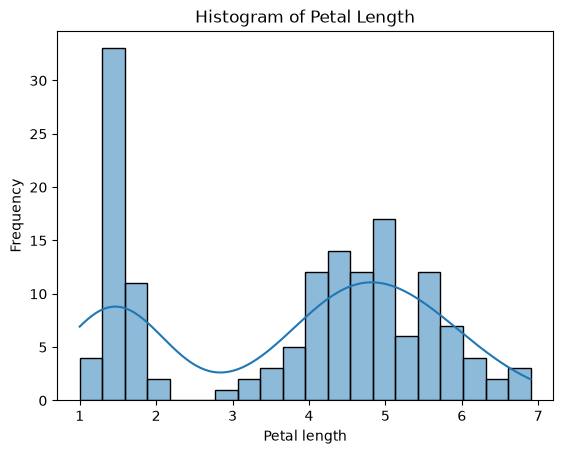

In [3]:
# Plotting seaborn histogram of the `petal_length` column in the iris dataset
# https://seaborn.pydata.org/generated/seaborn.histplot.html#seaborn-histplot

sns.histplot(data=iris_df,bins=20, x='petal_length', kde=True)

plt.title('Histogram of Petal Length')  
plt.xlabel('Petal length')  
plt.ylabel('Frequency')  
plt.show()

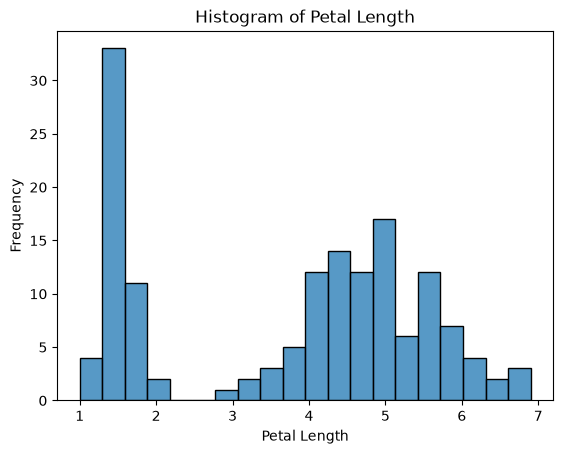

In [4]:
sns.histplot(data=iris_df, x='petal_length', bins=20)
plt.title('Histogram of Petal Length')
plt.xlabel('Petal Length')
plt.ylabel('Frequency')
plt.show()


In [5]:
# Calculating mean and standard deviation for the `petal_length` column in the iris dataset

mean_petal_length = iris_df['petal_length'].mean()
std_petal_length = iris_df['petal_length'].std()

In [6]:
# Print
print(f"Mean of Petal Length: {mean_petal_length}")
print(f"Standard Deviation of Petal Length: {std_petal_length}")

Mean of Petal Length: 3.7580000000000005
Standard Deviation of Petal Length: 1.7652982332594662


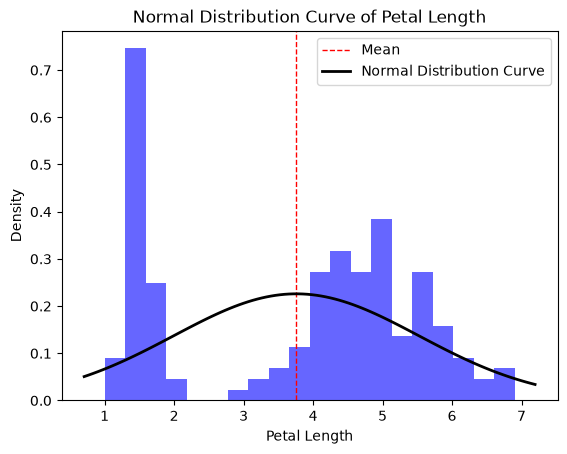

In [7]:
plt.hist(iris_df['petal_length'], bins=20, density=True, alpha=0.6, color='b')

# Preparing X values for plotting the normal distribution curve

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
y = stats.norm.pdf(x, mean_petal_length, std_petal_length)

# Adding vertical line for mean and plotting the normal distribution curve
plt.axvline(mean_petal_length, color='r', linestyle='dashed', linewidth=1, label='Mean')

# Adding curve
plt.plot(x, y, color='black', linewidth=2, label='Normal Distribution Curve')

plt.xlabel('Petal Length')
plt.ylabel('Density')   
plt.title('Normal Distribution Curve of Petal Length')  
plt.legend()
plt.show()

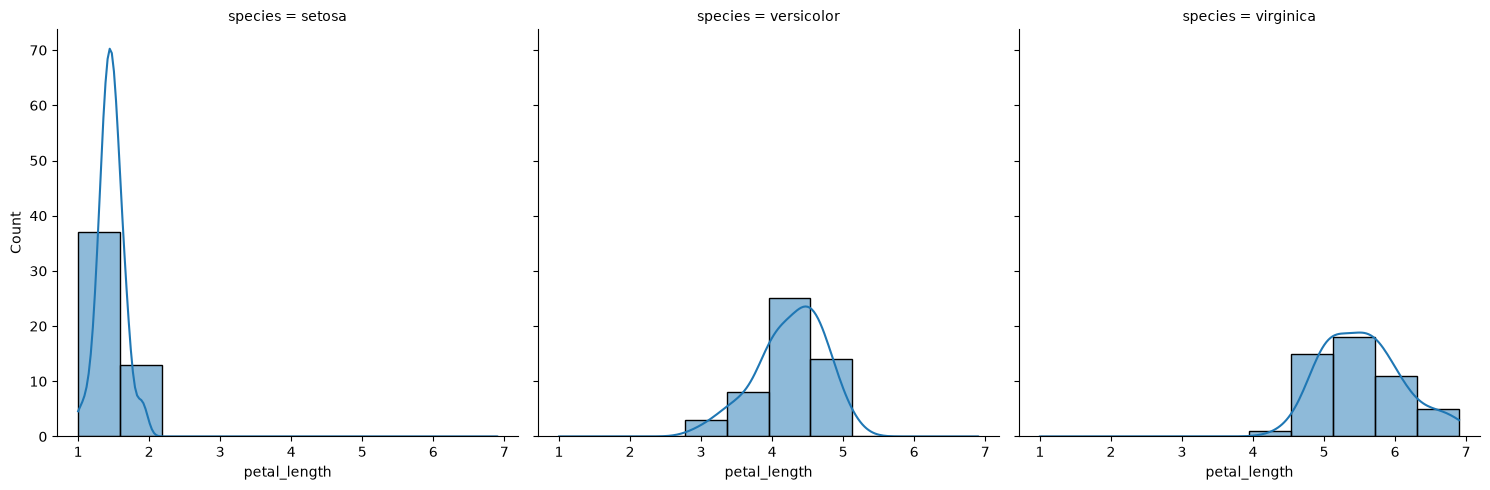

In [8]:
# Plotting seaborn histogram of the `petal_length` column in the iris dataset with species as hue
# https://seaborn.pydata.org/generated/seaborn.displot.html#seaborn-displot
sns.displot(data=iris_df, x='petal_length', col='species', bins=10, kde=True)
plt.show()

### What the Summary Statistics Show

The results show that the three flower species have different petal lengths.

Setosa flowers generally have much smaller petals than the other two species. Versicolor has larger petals than setosa, while virginica has the largest petal measurements.

The standard deviation gives an idea of how spread out the measurements are within each group. This is useful when comparing the variation between species.

These summary statistics provide a starting point for understanding the dataset before looking at the distributions in more detail.

In [9]:
# Calculating mean and standard deviation for the `petal_length` column in the iris dataset grouped by species
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html#pandas-dataframe-agg

species_stats = iris_df.groupby('species')['petal_length'].agg(['count', 'mean', 'std', 'min', 'max'])
print(species_stats.round(3))

            count   mean    std  min  max
species                                  
setosa         50  1.462  0.174  1.0  1.9
versicolor     50  4.260  0.470  3.0  5.1
virginica      50  5.552  0.552  4.5  6.9
